# Lab 10 Presentation - Neural Network Fundamentals and Convolutions

Josh Davis/Lucas Schwengber

# Learning goals

By the end of this lab you should be able to:

1.  Explain a shallow ReLU network as a sum of hinges, and why composing
    layers multiplies the number of linear pieces.
2.  Read and use a PyTorch training loop (cross-entropy, minibatches,
    optimizer steps), and diagnose a bad learning rate from the training
    loss.
3.  Interpret the last layer of a classifier as a logistic regression on
    features (an *embedding*) that the network learns.
4.  Explain why fully connected networks ignore where pixels are, and
    what this costs them on images.
5.  Explain how a convolutional layer works (weight sharing, channels,
    pooling), and count the parameters of a CNN.
6.  Use a validation set to detect overfitting, choose the number of
    epochs, and compare architectures.
7.  Make a CNN more robust to small shifts, through its architecture
    (depth and pooling) or with data augmentation.

Sections 1, 2 and 5 of this presentation go with parts 1 to 3 of the
[exercise](lab10_exercise.qmd). The exercise comes with a file,
`lab10_code.py`, that contains the code from this presentation it builds
on. Plotting code is folded.

We point to the relevant sections of *Understanding Deep Learning*
(Prince 2023), UDL below, which is free online at
[udlbook.github.io/udlbook](https://udlbook.github.io/udlbook/).

LLM assistance was used during the elaboration of this presentation and
the exercise.

# Setup

This lab uses PyTorch (`torch`) and `torchvision`, on top of the
packages we have used so far. If you cannot install them on your laptop,
[Google Colab](https://colab.research.google.com) has PyTorch
preinstalled and gives free (limited) access to a GPU under *Runtime →
Change runtime type*.

> **Installing PyTorch**
>
> We recommend a dedicated virtual environment. With `venv`, which comes
> with Python:
>
> ``` bash
> python -m venv stat154-env
> source stat154-env/bin/activate      # Mac/Linux
> stat154-env\Scripts\activate         # Windows
> pip install torch torchvision scikit-learn matplotlib ipykernel
> python -m ipykernel install --user --name=stat154-env
> ```
>
> With `conda`:
>
> ``` bash
> conda create -n stat154-env python=3.12
> conda activate stat154-env
> pip install torch torchvision scikit-learn matplotlib ipykernel
> python -m ipykernel install --user --name=stat154-env
> ```
>
> Then select the `stat154-env` kernel in Jupyter (*Kernel → Change
> Kernel*) or in VS Code.
>
> - **Mac with Apple silicon:** the commands above install a version
>   that can use the GPU through the `mps` device.
> - **NVIDIA GPU:** on Linux the default `pip` package already supports
>   NVIDIA GPUs. On Windows it is CPU-only; use the command from the
>   [PyTorch selector](https://pytorch.org/get-started/locally/) for
>   your CUDA version instead.
> - **Anything else:** the CPU version is fine. Everything in this
>   notebook runs on a laptop CPU.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

# use a GPU if there is one: "cuda" for NVIDIA GPUs, "mps" for Apple silicon
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"PyTorch {torch.__version__}, device: {device}")

PyTorch 2.15.0, device: mps

# Neural networks as functions

## A shallow network is a sum of hinges

The simplest neural network takes a scalar input $x$ and returns a
scalar output (Prince 2023, sec. 3.1):
$$f(x) = \phi_0 + \sum_{d=1}^{D} \phi_d \, a(\theta_{d0} + \theta_{d1} x),
\qquad a(z) = \mathrm{ReLU}(z) = \max(0, z).$$
As a diagram, with $D = 3$ hidden units:

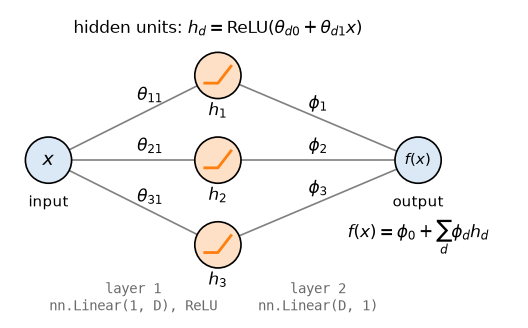

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
r = 0.3                                    # node radius
X_IN, X_HID, X_OUT = 0, 2.2, 4.8           # horizontal positions of the three columns
hidden_y = [1.1, 0, -1.1]                  # D = 3 hidden units


def node(x, y, color):
    ax.add_patch(plt.Circle((x, y), r, facecolor=color, edgecolor="black", lw=1.2, zorder=3))


for d, y in enumerate(hidden_y, start=1):
    ax.plot([X_IN, X_HID], [0, y], color="gray", lw=1.2, zorder=1)      # x -> h_d: weight theta_d1
    ax.plot([X_HID, X_OUT], [y, 0], color="gray", lw=1.2, zorder=1)     # h_d -> f(x): weight phi_d
    ax.text(X_IN + 0.6 * (X_HID - X_IN), 0.6 * y + 0.07, rf"$\theta_{{{d}1}}$", ha="center", va="bottom", fontsize=12)
    ax.text(X_HID + 0.5 * (X_OUT - X_HID), 0.5 * y + 0.07, rf"$\phi_{d}$", ha="center", va="bottom", fontsize=12)
    node(X_HID, y, "#fde0c5")
    ax.plot([X_HID - 0.17, X_HID, X_HID + 0.17], [y - 0.1, y - 0.1, y + 0.12], color="C1", lw=2, zorder=4)  # a hinge
    ax.text(X_HID, y - r - 0.05, rf"$h_{d}$", ha="center", va="top", fontsize=12)

node(X_IN, 0, "#dbe9f6")
ax.text(X_IN, 0, "$x$", ha="center", va="center", fontsize=14, zorder=4)
node(X_OUT, 0, "#dbe9f6")
ax.text(X_OUT, 0, "$f(x)$", ha="center", va="center", fontsize=11, zorder=4)

ax.text(X_IN, -0.6, "input", ha="center", fontsize=11)
ax.text(X_HID, 1.65, r"hidden units: $h_d = \mathrm{ReLU}(\theta_{d0} + \theta_{d1} x)$", ha="center", fontsize=12)
ax.text(X_OUT, -0.6, "output", ha="center", fontsize=11)
ax.text(X_OUT, -1.0, r"$f(x) = \phi_0 + \sum_d \phi_d h_d$", ha="center", fontsize=12)
for x_mid, label in [((X_IN + X_HID) / 2, "layer 1\nnn.Linear(1, D), ReLU"), ((X_HID + X_OUT) / 2, "layer 2\nnn.Linear(D, 1)")]:
    ax.text(x_mid, -1.95, label, ha="center", fontsize=10, family="monospace", color="dimgray")

ax.set_xlim(-0.5, 6.1)
ax.set_ylim(-2.05, 1.95)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

Each line carries a weight: $\theta_{d1}$ from the input to hidden unit
$d$, and $\phi_d$ from hidden unit $d$ to the output (the biases
$\theta_{d0}$ and $\phi_0$ are not drawn). The network has two layers of
weights, and each is an `nn.Linear` layer in PyTorch.

> **Example: the network with numbers**
>
> Give the parameters these values:
>
> | hidden unit $d$ | bias $\theta_{d0}$ | weight $\theta_{d1}$ | weight $\phi_d$ |
> |:----------------:|:----------------:|:----------------:|:----------------:|
> |        1        |        $1$         |         $1$          |       $1$       |
> |        2        |        $-1$        |         $2$          |      $-2$       |
> |        3        |        $1$         |         $-1$         |      $0.5$      |
>
> and $\phi_0 = 0.5$. Here is what the network does with the input
> $x = 1.5$. Each node shows its value; hidden unit 3 is grayed out
> because it is off.
>
> ``` python
> theta0 = [1, -1, 1]              # biases theta_d0
> theta1 = [1, 2, -1]              # weights theta_d1
> phi0, phi = 0.5, [1, -2, 0.5]    # bias phi_0 and weights phi_d
> x_in = 1.5
> h = [max(0, t0 + t1 * x_in) for t0, t1 in zip(theta0, theta1)]    # layer 1
> f_out = phi0 + sum(p * hd for p, hd in zip(phi, h))                 # layer 2
>
>
> def fmt(v):
>     return f"{v:g}".replace("-", "\N{MINUS SIGN}")
>
>
> fig, (ax, ax_f) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
> r = 0.32
> X_IN, X_HID, X_OUT = 0, 2.7, 5.7
> hidden_y = [1.6, 0, -1.6]
>
>
> def node(x, y, color, value):
>     ax.add_patch(plt.Circle((x, y), r, facecolor=color, edgecolor="black", lw=1.2, zorder=3))
>     ax.text(x, y, fmt(value), ha="center", va="center", fontsize=13, zorder=4)
>
>
> label_box = dict(facecolor="white", edgecolor="none", pad=1)
> for d, y in enumerate(hidden_y):
>     on = h[d] > 0
>     style = dict(color="gray", lw=1.2, zorder=1) if on else dict(color="lightgray", lw=1.2, ls="--", zorder=1)
>     ax.plot([X_IN, X_HID], [0, y], **style)
>     ax.plot([X_HID, X_OUT], [y, 0], **style)
>     ax.text(X_IN + 0.42 * (X_HID - X_IN), 0.42 * y + 0.08, rf"$\theta_{{{d + 1}1}} = {theta1[d]}$",
>             ha="center", va="bottom", fontsize=11, bbox=label_box)
>     ax.text(X_HID + 0.58 * (X_OUT - X_HID), 0.42 * y + 0.08, rf"$\phi_{d + 1} = {phi[d]:g}$",
>             ha="center", va="bottom", fontsize=11, bbox=label_box)
>     node(X_HID, y, "#fde0c5" if on else "#eeeeee", h[d])
>     ax.text(X_HID, y - r - 0.06, rf"$h_{d + 1}$, bias $\theta_{{{d + 1}0}} = {theta0[d]}$",
>             ha="center", va="top", fontsize=10, bbox=label_box)
>
> node(X_IN, 0, "#dbe9f6", x_in)
> node(X_OUT, 0, "#dbe9f6", f_out)
> ax.text(X_IN, -r - 0.1, "input $x$", ha="center", va="top", fontsize=11)
> ax.text(X_OUT, -r - 0.1, "output $f(x)$\n" + rf"bias $\phi_0 = {phi0:g}$", ha="center", va="top", fontsize=11)
> ax.text(X_HID, 2.25, r"hidden units: $h_d = \mathrm{ReLU}(\theta_{d0} + \theta_{d1} x)$", ha="center", fontsize=12)
> ax.set_xlim(-0.5, X_OUT + 0.9)
> ax.set_ylim(-2.35, 2.65)
> ax.set_aspect("equal")
> ax.axis("off")
>
> # right: the whole function f, with the point (x_in, f(x_in)) computed on the left
> x_grid = np.linspace(-2.5, 2.5, 501)
> f_grid = phi0 + sum(p * np.maximum(0, t0 + t1 * x_grid) for t0, t1, p in zip(theta0, theta1, phi))
> ax_f.plot(x_grid, f_grid, color="C1", lw=2)
> for t0, t1 in zip(theta0, theta1):
>     ax_f.axvline(-t0 / t1, color="C0", lw=0.6, alpha=0.6)
> ax_f.plot([x_in, x_in, -2.5], [-3.2, f_out, f_out], "k:", lw=1)
> ax_f.plot(x_in, f_out, "o", color="black", ms=6, zorder=3)
> ax_f.annotate(rf"$f({x_in:g}) = {f_out:g}$", (x_in, f_out), xytext=(-1.6, -1.9), fontsize=11,
>               arrowprops=dict(arrowstyle="->", color="black", lw=0.8))
> ax_f.set_xlim(-2.5, 2.5)
> ax_f.set_ylim(-3.2, 3)
> ax_f.set_xlabel("$x$")
> ax_f.set_title("the same network for every $x$", fontsize=11)
> plt.tight_layout()
> plt.show()
> ```
>
> 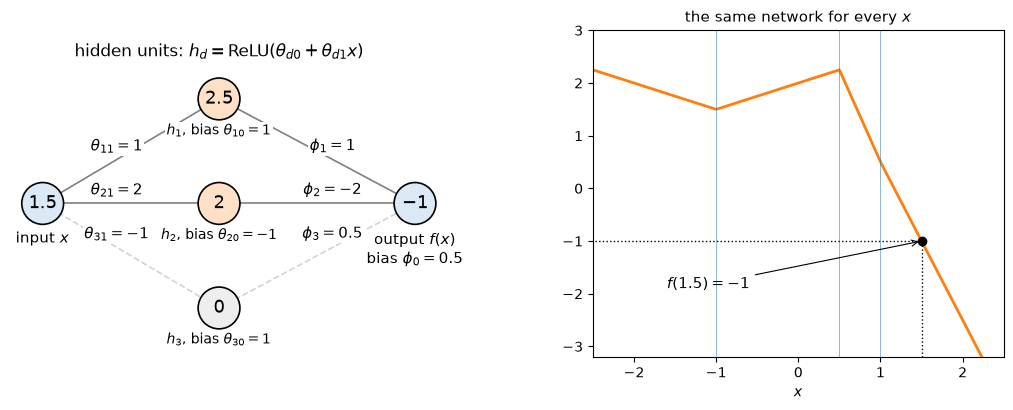
>
> **Layer 1.** Each hidden unit computes $\theta_{d0} + \theta_{d1} x$
> and applies the ReLU:
> $$\begin{aligned}
> h_1 &= \mathrm{ReLU}(1 + 1 \cdot 1.5) = \mathrm{ReLU}(2.5) = 2.5, \\
> h_2 &= \mathrm{ReLU}(-1 + 2 \cdot 1.5) = \mathrm{ReLU}(2) = 2, \\
> h_3 &= \mathrm{ReLU}(1 + (-1) \cdot 1.5) = \mathrm{ReLU}(-0.5) = 0.
> \end{aligned}$$
>
> **Layer 2.** The output is $\phi_0$ plus the weighted sum of the
> hidden units:
> $$f(1.5) = \phi_0 + \phi_1 h_1 + \phi_2 h_2 + \phi_3 h_3 = 0.5 + 1 \cdot 2.5 + (-2) \cdot 2 + 0.5 \cdot 0 = -1.$$
>
> Hidden unit 3 is *off* at $x = 1.5$: its input $1 - 1.5$ is negative,
> so the ReLU outputs $0$ and $\phi_3$ has no effect on $f(1.5)$. Doing
> this for every $x$ gives the function on the right. Its slope changes
> at $x = -1$, $0.5$ and $1$ (blue lines), where one of the hidden units
> switches on or off.

Each of the $D$ *hidden units* $h_d(x) = a(\theta_{d0} + \theta_{d1} x)$
is a “hinge”: it is zero on one side of its *joint*
$x = -\theta_{d0}/\theta_{d1}$ and linear on the other. So $f$ is
piecewise linear with at most $D$ joints. It is a linear spline, as in
lab 2, except that the knots are learned from the data together with the
coefficients.

Below we fit networks with $D = 3$, $10$ and $50$ hidden units to noisy
data by least squares, with gradient descent
(<a href="#sec-training" class="quarto-xref">Section 2.2</a>).

In [4]:
def target(x):
    return np.sin(2 * x) + 0.3 * x**2


rng = np.random.default_rng(0)
x_reg = rng.uniform(-3, 3, size=200)
y_reg = target(x_reg) + 0.2 * rng.standard_normal(200)
X_reg = torch.tensor(x_reg, dtype=torch.float32).reshape(-1, 1)    # PyTorch wants an (n, p) array of floats
Y_reg = torch.tensor(y_reg, dtype=torch.float32).reshape(-1, 1)


class ShallowNet(nn.Module):
    """f(x) = phi_0 + sum_d phi_d ReLU(theta_d0 + theta_d1 x), with D hidden units."""

    def __init__(self, D):
        super().__init__()
        self.hidden = nn.Linear(1, D)    # the thetas: weight (D, 1) holds the slopes theta_d1, bias (D,) the theta_d0
        self.output = nn.Linear(D, 1)    # the phis: weight (1, D) holds phi_1, ..., phi_D, bias (1,) holds phi_0

    def hidden_units(self, x):
        return torch.relu(self.hidden(x))

    def forward(self, x):
        return self.output(self.hidden_units(x))

    def joints(self):
        """The points x = -theta_d0 / theta_d1 where each hidden unit switches on or off."""
        return (-self.hidden.bias / self.hidden.weight[:, 0]).detach().numpy()


def fit_least_squares(model, X, Y, n_steps=3000, lr=0.01):
    """Minimize the mean squared error by full-batch gradient descent (with the Adam optimizer)."""
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for step in range(n_steps):
        optimizer.zero_grad()
        loss = ((model(X) - Y) ** 2).mean()
        loss.backward()
        optimizer.step()
    return model


torch.manual_seed(1)
shallow_nets = {D: fit_least_squares(ShallowNet(D), X_reg, Y_reg) for D in [3, 10, 50]}

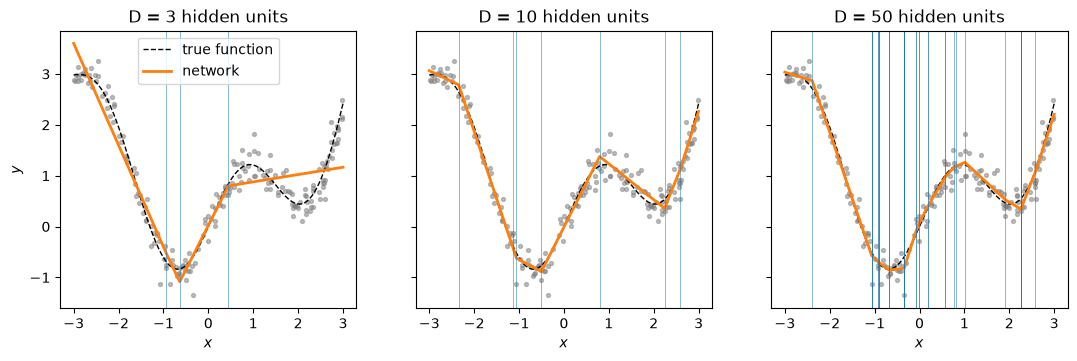

In [5]:
x_grid = np.linspace(-3, 3, 600)
X_grid = torch.tensor(x_grid, dtype=torch.float32).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (D, net) in zip(axes, shallow_nets.items()):
    with torch.no_grad():
        f_hat = net(X_grid).numpy().ravel()
    ax.scatter(x_reg, y_reg, s=8, color="gray", alpha=0.5)
    ax.plot(x_grid, target(x_grid), "k--", lw=1, label="true function")
    ax.plot(x_grid, f_hat, color="C1", lw=2, label="network")
    for j in net.joints():
        if -3 < j < 3:
            ax.axvline(j, color="C0", lw=0.6, alpha=0.6)
    ax.set_title(f"D = {D} hidden units")
    ax.set_xlabel("$x$")
axes[0].set_ylabel("$y$")
axes[0].legend(loc="upper center")
plt.show()

The blue vertical lines are the joints. Three hinges are too few to
follow the target, while ten are enough.

## Reading the parameters off the picture

Every parameter has a geometric meaning. Here is the $D = 3$ network
split into its weighted hinges $\phi_d h_d(x)$:

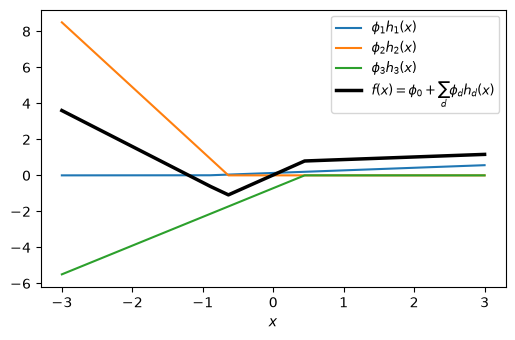

In [6]:
net = shallow_nets[3]
with torch.no_grad():
    H = net.hidden_units(X_grid).numpy()     # (600, D): the hidden units h_d(x) on the grid
    phi = net.output.weight[0].numpy()       # (D,): the output weights phi_d
    phi0 = net.output.bias.item()

fig, ax = plt.subplots(figsize=(6, 3.6))
for d in range(H.shape[1]):
    ax.plot(x_grid, phi[d] * H[:, d], lw=1.5, label=f"$\\phi_{d + 1} h_{d + 1}(x)$")
ax.plot(x_grid, phi0 + H @ phi, "k", lw=2.5, label="$f(x) = \\phi_0 + \\sum_d \\phi_d h_d(x)$")
ax.set_xlabel("$x$")
ax.legend(fontsize=9)
plt.show()

- Unit $d$ has its joint at $x = -\theta_{d0}/\theta_{d1}$. It is on to
  the right of the joint if $\theta_{d1} > 0$, and to the left if
  $\theta_{d1} < 0$.
- Crossing the joint of unit $d$ from left to right changes the slope of
  $f$ by $\phi_d |\theta_{d1}|$.
- $\phi_0$ moves the whole function up or down.

So to draw a piecewise linear function, put one hidden unit at each
kink, with the output weight that changes the slope by the right amount.
For example, $\mathrm{ReLU}(x - 1) - \mathrm{ReLU}(x - 2)$ is $0$ up to
$x = 1$, rises with slope $1$ up to $x = 2$, and stays at $1$ after.
Training finds such parameters by itself, starting from random values;
with another seed, two units might share a joint, or a unit might be
zero on all the data (a “dead” unit).

With enough hidden units, a shallow network can approximate any
continuous function on a bounded set as closely as we want: this is the
*universal approximation theorem* (Cybenko 1989; Hornik 1991; Leshno et
al. 1993; Prince 2023, sec. 3.2). It does not say how many units are
needed, or whether training finds them.

## Depth multiplies the linear pieces

A *deep* network applies several layers of hidden units in sequence: the
output of each layer is the input of the next (Prince 2023, ch. 4). To
see why this helps, compose two shallow networks $f_1$ and $f_2$ with
three hidden units each into $f_2(f_1(x))$ (Prince 2023, sec. 4.1).
Below, $f_1$ is a zigzag that sweeps the interval $[0, 1]$ three times
as $x$ goes from $0$ to $1$.

In [7]:
def relu(z):
    return np.maximum(z, 0)


def f1(x):
    """Shallow network with 3 hidden units: a zigzag that sweeps [0, 1] three times as x goes from 0 to 1."""
    return 3 * relu(x) - 6 * relu(x - 1 / 3) + 6 * relu(x - 2 / 3)


def f2(u):
    """Another shallow network with 3 hidden units."""
    return -0.5 + 2 * relu(u) - 5 * relu(u - 0.4) + 4 * relu(u - 0.75)

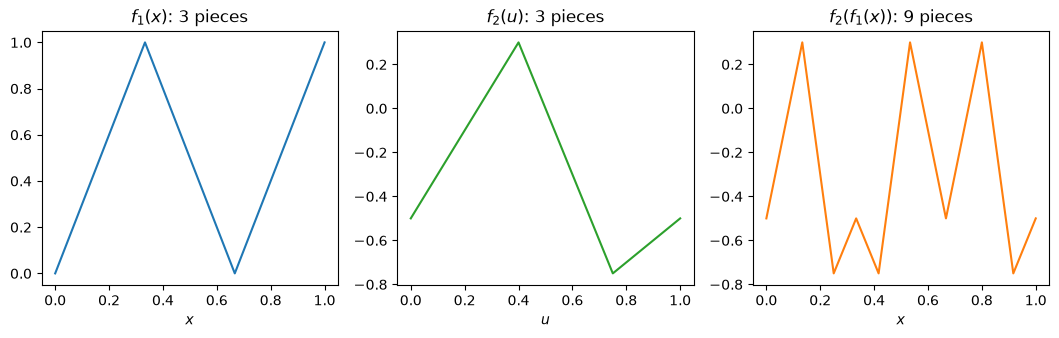

In [8]:
x = np.linspace(0, 1, 1201)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].plot(x, f1(x), color="C0")
axes[0].set(title="$f_1(x)$: 3 pieces", xlabel="$x$")
axes[1].plot(x, f2(x), color="C2")
axes[1].set(title="$f_2(u)$: 3 pieces", xlabel="$u$")
axes[2].plot(x, f2(f1(x)), color="C1")
axes[2].set(title="$f_2(f_1(x))$: 9 pieces", xlabel="$x$")
plt.show()

Each time $f_1$ sweeps $[0, 1]$, the composition traces out all of
$f_2$, so $f_2(f_1(x))$ has $3 \times 3 = 9$ linear pieces from 6 hidden
units. A shallow network with $D$ hidden units has at most $D$ joints,
so at most $D + 1$ pieces. Each additional layer of this kind multiplies
the number of pieces by 3, but adds only 3 hidden units. In general, the
number of linear regions can grow exponentially with depth, but only
polynomially with width (Montúfar et al. 2014; Prince 2023, sec. 4.5);
trained networks do not necessarily use that many regions (Hanin and
Rolnick 2019).

With an input vector $\boldsymbol{x}$, layer $k$ computes
$\boldsymbol{h}_{k+1} = a(\boldsymbol{\beta}_k + \boldsymbol{\Omega}_k \boldsymbol{h}_k)$,
with $a$ applied to each coordinate (Prince 2023, sec. 4.4). In PyTorch,
this is an `nn.Linear` layer followed by `nn.ReLU()`.

# Classifiers learn their own features

## Logistic regression on learned features

For $K$ classes, the network outputs $K$ *logits*
$\ell_1(\boldsymbol{x}), \ldots, \ell_K(\boldsymbol{x})$, which the
softmax turns into probabilities,
$\mathbb{P}_{\,}\left(y = k \mid \boldsymbol{x}\right) = \exp(\ell_k(\boldsymbol{x})) / \sum_{j=1}^K \exp(\ell_j(\boldsymbol{x}))$.
It is fit by minimizing the *cross-entropy*
$-\sum_{n=1}^N\log \mathbb{P}_{\,}\left(y_n \mid \boldsymbol{x}_n\right)$,
the negative log-likelihood (Prince 2023, sec. 5.5); for $K = 2$, this
is the logistic loss from lab 7.

Split the network in two: the first layers compute an *embedding*
$\boldsymbol{z}(\boldsymbol{x}) \in \mathbb{R}^q$, and the last layer is
linear,
$\ell_k(\boldsymbol{x}) = \beta_k + \boldsymbol{w}_k^\intercal\boldsymbol{z}(\boldsymbol{x})$.
So the last layer is a logistic regression whose features are learned
along with its coefficients. Here is a data set where logistic
regression on the raw features fails:

logistic regression on (x1, x2):    training accuracy 50.2%
logistic regression on x1^2 + x2^2: training accuracy 99.9%

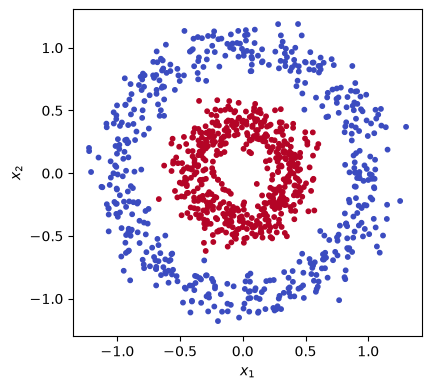

In [9]:
from sklearn.datasets import make_circles
from sklearn.linear_model import LogisticRegression

X_circ, y_circ = make_circles(n_samples=1000, noise=0.1, factor=0.4, random_state=0)

r2 = (X_circ**2).sum(axis=1, keepdims=True)    # the hand-made feature x1^2 + x2^2
acc_raw = LogisticRegression().fit(X_circ, y_circ).score(X_circ, y_circ)
acc_r2 = LogisticRegression().fit(r2, y_circ).score(r2, y_circ)
print(f"logistic regression on (x1, x2):    training accuracy {acc_raw:.1%}")
print(f"logistic regression on x1^2 + x2^2: training accuracy {acc_r2:.1%}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(X_circ[:, 0], X_circ[:, 1], c=y_circ, cmap="coolwarm", s=10)
ax.set_xlabel("$x_1$")
ax.set_ylabel("$x_2$")
ax.set_aspect("equal")
plt.show()

A straight line cannot separate the circles, but a threshold on
$x_1^2 + x_2^2$ can. Does a network find such a feature by itself? Ours
has two hidden layers of 16 units and a **2-dimensional embedding**, so
that we can plot it.

In [10]:
class CircleNet(nn.Module):
    def __init__(self, hidden=16, embed_dim=2, n_classes=2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(2, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, embed_dim),          # the embedding z(x)
        )
        self.classifier = nn.Linear(embed_dim, n_classes)    # logistic regression on z(x)

    def embedding(self, x):
        return self.encoder(x)

    def forward(self, x):
        return self.classifier(self.embedding(x))      # the logits

## Training with gradient descent

Training minimizes the loss $\mathscr{L}(\phi)$ over all the parameters
$\phi$ by gradient descent,
$\phi \leftarrow \phi - \alpha \nabla_\phi \mathscr{L}(\phi)$, with a
*learning rate* $\alpha$ (Prince 2023, ch. 6).

- **Backpropagation** computes all the partial derivatives at once with
  the chain rule, at about the cost of evaluating the network (Rumelhart
  et al. 1986; Prince 2023, ch. 7). In PyTorch, `loss.backward()` stores
  them in `p.grad` for every parameter `p`.
- **Stochastic gradient descent (SGD)** uses the gradient on a small
  random *minibatch* instead of the full data set: the steps are noisy
  but cheap. One pass over all the minibatches is an *epoch* (Prince
  2023, sec. 6.2).

Every PyTorch training loop has the same five steps:

In [11]:
X_circ_t = torch.tensor(X_circ, dtype=torch.float32)
y_circ_t = torch.tensor(y_circ)                # class labels as integers 0, ..., K - 1
circle_data = torch.utils.data.TensorDataset(X_circ_t, y_circ_t)


def train_circle_net(lr, optimizer_class=torch.optim.Adam, embed_dim=2, n_epochs=50, batch_size=32, seed=0):
    torch.manual_seed(seed)
    net = CircleNet(embed_dim=embed_dim)
    loader = torch.utils.data.DataLoader(circle_data, batch_size=batch_size, shuffle=True)
    optimizer = optimizer_class(net.parameters(), lr=lr)
    epoch_losses = []
    for epoch in range(n_epochs):
        for xb, yb in loader:                     # one epoch = one pass over all the minibatches
            optimizer.zero_grad()                 # 1. reset the gradients from the previous step
            logits = net(xb)                      # 2. forward pass
            loss = F.cross_entropy(logits, yb)    # 3. softmax + negative log-likelihood, averaged over the batch
            loss.backward()                       # 4. backpropagation: fills p.grad for every parameter p
            optimizer.step()                      # 5. gradient step
        with torch.no_grad():                     # no gradients needed to evaluate the loss
            epoch_losses.append(F.cross_entropy(net(X_circ_t), y_circ_t).item())
    return net, epoch_losses


circle_net, _ = train_circle_net(lr=1e-2)

## Choosing the learning rate

Here is the same network trained with the Adam optimizer (see below) and
three learning rates:

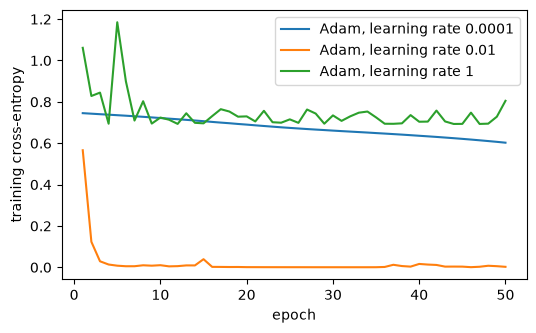

In [12]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for lr in [1e-4, 1e-2, 1.0]:
    _, losses = train_circle_net(lr=lr)
    ax.plot(range(1, len(losses) + 1), losses, label=f"Adam, learning rate {lr:g}")
ax.set_xlabel("epoch")
ax.set_ylabel("training cross-entropy")
ax.legend(loc="upper right")
plt.show()

With $10^{-4}$ the loss barely moves in 50 epochs, and with $1$ it never
settles. The learning rate is usually the first hyperparameter to tune
(Prince 2023, sec. 6.5), and good values depend on the optimizer:

- **Plain SGD** moves each parameter by $\alpha$ times its partial
  derivative. If $\alpha$ is too small, training crawls. If it is too
  large, each step overshoots the minimum in the steep directions and
  lands where the gradient is even larger; the parameters blow up and
  the loss becomes `nan` (“not a number”).
- **Adam** divides each partial derivative by a running estimate of its
  typical size, so each parameter moves by roughly $\alpha$ per step,
  whatever the scale of the gradient (Kingma and Ba 2015; Prince 2023,
  sec. 6.4). Values around $10^{-3}$ work for many problems, while good
  learning rates for SGD vary more from problem to problem and are often
  larger.

These are training losses: they tell us whether the optimization works,
not whether the network generalizes.

## What the network learned

Here is the circle network as a diagram. The first three layers, the
*encoder*, compute the embedding
$\boldsymbol{z}(\boldsymbol{x}) = (z_1, z_2)$, and the last layer is a
logistic regression on it:

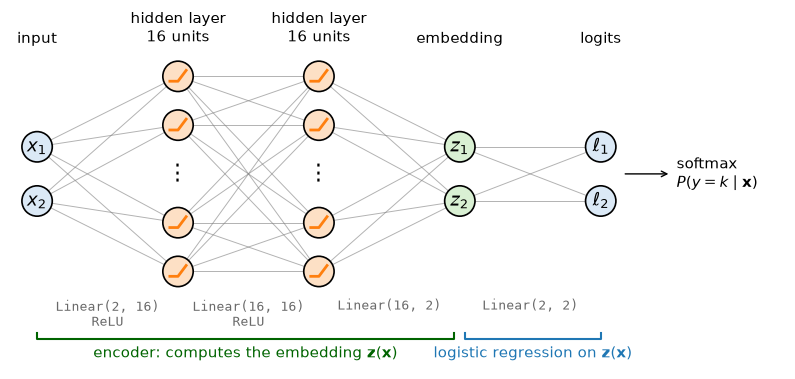

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
r = 0.28                                                       # node radius
S = 2.6                                                        # horizontal spacing between layers
BLUE, ORANGE, GREEN = "#dbe9f6", "#fde0c5", "#d9f0d3"
columns = [                                                    # (x position, node heights, color, node labels)
    (0 * S, [0.5, -0.5], BLUE, ["$x_1$", "$x_2$"]),
    (1 * S, [1.8, 0.9, -0.9, -1.8], ORANGE, None),             # 16 hidden units, 4 of them drawn
    (2 * S, [1.8, 0.9, -0.9, -1.8], ORANGE, None),
    (3 * S, [0.5, -0.5], GREEN, ["$z_1$", "$z_2$"]),
    (4 * S, [0.5, -0.5], BLUE, [r"$\ell_1$", r"$\ell_2$"]),
]

for (x0, ys0, _, _), (x1, ys1, _, _) in zip(columns[:-1], columns[1:]):    # every unit feeds every unit of the next layer
    for y0 in ys0:
        for y1 in ys1:
            ax.plot([x0, x1], [y0, y1], color="gray", lw=0.7, alpha=0.6, zorder=1)

for x, ys, color, labels in columns:
    for i, y in enumerate(ys):
        ax.add_patch(plt.Circle((x, y), r, facecolor=color, edgecolor="black", lw=1.2, zorder=3))
        if labels is None:
            ax.plot([x - 0.15, x, x + 0.15], [y - 0.09, y - 0.09, y + 0.11], color="C1", lw=2, zorder=4)   # a hinge
        else:
            ax.text(x, y, labels[i], ha="center", va="center", fontsize=13, zorder=4)
    if labels is None:
        ax.text(x, 0, r"$\vdots$", ha="center", va="center", fontsize=16)

for i, title in enumerate(["input", "hidden layer\n16 units", "hidden layer\n16 units", "embedding", "logits"]):
    ax.text(i * S, 2.35, title, ha="center", va="bottom", fontsize=11)
ax.annotate("", xy=(4 * S + 1.3, 0), xytext=(4 * S + 0.4, 0), arrowprops=dict(arrowstyle="->", color="black"))
ax.text(4 * S + 1.4, 0, "softmax\n" + r"$P(y = k \mid \mathbf{x})$", ha="left", va="center", fontsize=11)

for i, label in enumerate(["Linear(2, 16)\nReLU", "Linear(16, 16)\nReLU", "Linear(16, 2)", "Linear(2, 2)"]):
    ax.text((i + 0.5) * S, -2.3, label, ha="center", va="top", fontsize=9, family="monospace", color="dimgray")


def bracket(x_start, x_end, y, text, color):
    ax.plot([x_start, x_start, x_end, x_end], [y + 0.12, y, y, y + 0.12], color=color, lw=1.5)
    ax.text((x_start + x_end) / 2, y - 0.12, text, ha="center", va="top", fontsize=11, color=color)


bracket(0, 3 * S - 0.1, -3.05, r"encoder: computes the embedding $\mathbf{z}(\mathbf{x})$", "darkgreen")
bracket(3 * S + 0.1, 4 * S, -3.05, r"logistic regression on $\mathbf{z}(\mathbf{x})$", "C0")

ax.set_xlim(-0.5, 4 * S + 3.4)
ax.set_ylim(-3.6, 2.95)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

Here is that network after training with Adam and learning rate
$10^{-2}$, in the input space and in its embedding:

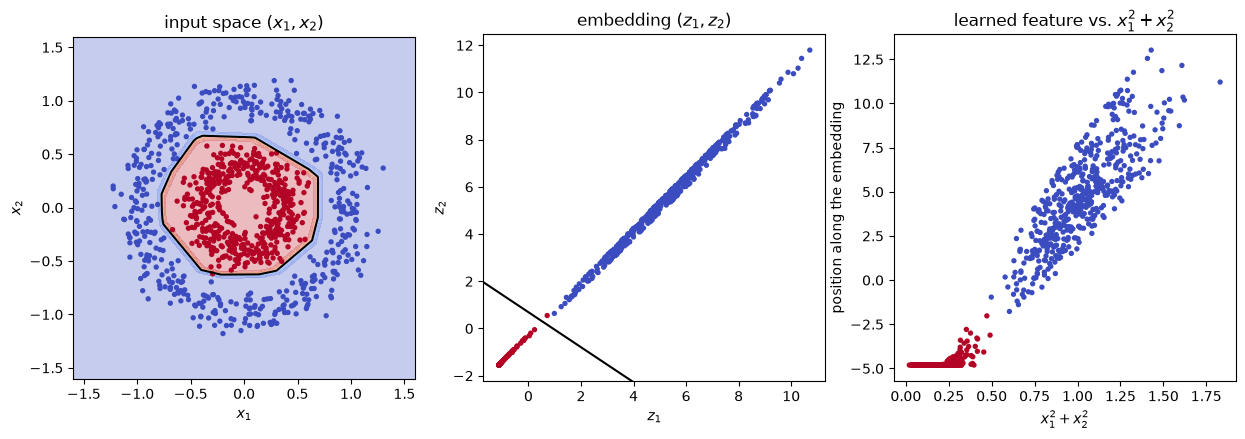

In [14]:
grid = np.linspace(-1.6, 1.6, 300)
g1, g2 = np.meshgrid(grid, grid)
G = torch.tensor(np.column_stack([g1.ravel(), g2.ravel()]), dtype=torch.float32)

circle_net.eval()
with torch.no_grad():
    prob_grid = torch.softmax(circle_net(G), dim=1)[:, 1].reshape(g1.shape).numpy()    # P(y = 1 | x) on a grid
    Z_circ = circle_net.embedding(X_circ_t).numpy()
    w = circle_net.classifier.weight.numpy()
    b = circle_net.classifier.bias.numpy()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].contourf(g1, g2, prob_grid, levels=20, cmap="coolwarm", alpha=0.3)
axes[0].contour(g1, g2, prob_grid, levels=[0.5], colors="k")
axes[0].scatter(X_circ[:, 0], X_circ[:, 1], c=y_circ, cmap="coolwarm", s=8)
axes[0].set(title="input space $(x_1, x_2)$", xlabel="$x_1$", ylabel="$x_2$")
axes[0].set_aspect("equal")

axes[1].scatter(Z_circ[:, 0], Z_circ[:, 1], c=y_circ, cmap="coolwarm", s=8)
xlim, ylim = axes[1].get_xlim(), axes[1].get_ylim()
# the classifier predicts class 1 when (w_1 - w_0)^T z + (b_1 - b_0) > 0, a straight line in the embedding
dw, db = w[1] - w[0], b[1] - b[0]
z1 = np.linspace(*xlim, 100)
axes[1].plot(z1, -(db + dw[0] * z1) / dw[1], "k")
axes[1].set(xlim=xlim, ylim=ylim, title="embedding $(z_1, z_2)$", xlabel="$z_1$", ylabel="$z_2$")

# position of each point along the main direction of the embedding (its first principal component)
Z_centered = Z_circ - Z_circ.mean(axis=0)
pc1 = Z_centered @ np.linalg.svd(Z_centered, full_matrices=False)[2][0]
axes[2].scatter(r2[:, 0], pc1, c=y_circ, cmap="coolwarm", s=8)
axes[2].set(title="learned feature vs. $x_1^2 + x_2^2$", xlabel="$x_1^2 + x_2^2$",
            ylabel="position along the embedding")
plt.show()

In the input space, the decision boundary (black) is a closed polygon,
since the network is piecewise linear. In the embedding, it is a
straight line: the first layers have transformed the data so that the
final logistic regression is easy. The embedding is almost
one-dimensional, and the position of a point along it is an increasing
function of $x_1^2 + x_2^2$ (third panel). The network found by itself a
feature that does the job of the one we designed by hand.

So a 1-dimensional embedding would do. With a single feature
$z(\boldsymbol{x})$, the last layer can only set a threshold, predicting
one class above a cutoff and the other below; that works as long as the
first layers make $z(\boldsymbol{x})$ larger on one circle than on the
other. In general, the embedding needs enough dimensions for the classes
to become linearly separable in it.

# Fully connected networks on images

MNIST (LeCun et al. 1998) has 70,000 grayscale $28 \times 28$ images of
handwritten digits: 50,000 for training, 10,000 for validation and
10,000 for testing. The folded code loads it, defines `train` and
`evaluate` (the training loop of
<a href="#sec-training" class="quarto-xref">Section 2.2</a>, with
minibatches, a validation set and an optional `transform` applied to the
images), and trains two models on the 784 pixels: logistic regression,
and a fully connected network with two hidden layers of 128 units
(`make_mlp`).

In [15]:
from torchvision import datasets, transforms

# ToTensor turns each image into a float tensor of shape (1, 28, 28) with values in [0, 1]
train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transforms.ToTensor())
test_set = datasets.MNIST(root="./data", train=False, download=True, transform=transforms.ToTensor())
train_set, val_set = torch.utils.data.random_split(train_full, [50_000, 10_000],
                                                   generator=torch.Generator().manual_seed(0))

train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True)   # minibatches for SGD
val_loader = torch.utils.data.DataLoader(val_set, batch_size=1000)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=1000)


def evaluate(model, loader, transform=None):
    """Average cross-entropy and accuracy of the model on a data set."""
    model.eval()
    total_loss, n_correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            if transform is not None:
                xb = transform(xb)
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
            n_correct += (logits.argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, n_correct / n


def train(model, train_loader, n_epochs, lr=1e-3, weight_decay=0.0, transform=None, verbose=True):
    """Train with Adam. After each epoch, record the training loss (the average of the minibatch losses during
    the epoch, which is cheap to compute but lags a little behind) and the validation loss and accuracy."""
    model.to(device)      # the GPU, if there is one
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        model.train()      # model.train() and model.eval() matter for layers like dropout; a good habit
        total_loss, n = 0.0, 0
        for xb, yb in train_loader:
            if transform is not None:
                xb = transform(xb)
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(yb)
            n += len(yb)
        val_loss, val_acc = evaluate(model, val_loader, transform)
        history["train_loss"].append(total_loss / n)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"  epoch {epoch + 1:2d}: training loss {total_loss / n:.3f}, "
                  f"validation loss {val_loss:.3f}, validation accuracy {val_acc:.1%}")
    return history


xb, yb = next(iter(train_loader))
print(f"{len(train_set)} training, {len(val_set)} validation and {len(test_set)} test images")
print(f"a minibatch of images has shape {tuple(xb.shape)} = (batch, channels, height, width)")

50000 training, 10000 validation and 10000 test images
a minibatch of images has shape (128, 1, 28, 28) = (batch, channels, height, width)

In [16]:
def make_logistic_regression():
    # started from zero, and trained with a small ridge penalty (weight_decay), so that its weights are easy to look at
    model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10))
    nn.init.zeros_(model[1].weight)
    nn.init.zeros_(model[1].bias)
    return model


def make_mlp():
    return nn.Sequential(
        nn.Flatten(),                                  # (batch, 1, 28, 28) -> (batch, 784)
        nn.Linear(28 * 28, 128), nn.ReLU(),
        nn.Linear(128, 128), nn.ReLU(),
        nn.Linear(128, 10),                            # the 10 logits
    )


N_EPOCHS = 5
models, histories = {}, {}
for name, make, weight_decay in [("logistic regression", make_logistic_regression, 1e-3),
                                 ("fully connected", make_mlp, 0.0)]:
    torch.manual_seed(0)
    models[name] = make()
    histories[name] = train(models[name], train_loader, N_EPOCHS, weight_decay=weight_decay, verbose=False)
    print(f"{name:<20} test accuracy {evaluate(models[name], test_loader)[1]:.1%}")

logistic regression  test accuracy 91.9%
fully connected      test accuracy 97.3%

The fully connected network gets 97% of the test digits right, and
section 1 says that a large enough network can approximate any function.
Yet plain fully connected networks are rarely used on images, because
they do not know that their input is an image.

**Each weight belongs to one pixel position.** In logistic regression,
the logit of class $k$ is
$\beta_k + \boldsymbol{w}_k^\intercal\boldsymbol{x}$, so we can draw
$\boldsymbol{w}_k$ as a $28 \times 28$ image: red where ink pushes the
prediction towards class $k$, blue where it pushes away.

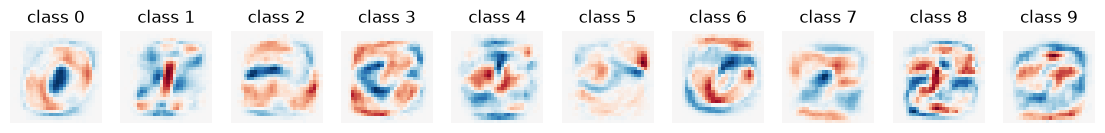

In [17]:
W = models["logistic regression"][1].weight.detach().cpu()      # shape (10, 784): one row per class

fig, axes = plt.subplots(1, 10, figsize=(14, 1.9))
for k, ax in enumerate(axes):
    v = W[k].abs().max()
    ax.imshow(W[k].reshape(28, 28), cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(f"class {k}")
    ax.axis("off")
plt.show()

Each weight image is a template at a fixed position: the 0 is a red ring
with a blue center, the 1 a red vertical stroke. The hidden units of the
fully connected network can be drawn the same way, and they are tied to
fixed positions too.

**Nothing says which pixels are neighbors.** If we scramble the pixels,
with the same permutation for every image, the digits become noise to us
but not to the network: scrambling only permutes the columns of its
first weight matrix, so it can learn the scrambled digits just as well.
It does not use the fact that nearby pixels are related.

**A shifted digit is a new input.** A digit moved by 3 pixels puts its
ink on other weights, so the network has to learn from examples,
separately at every position, that it is the same digit. In section 5,
its accuracy drops to about 50% on test digits shifted by 3 pixels.

**The first layer grows with the image.** It has one weight per pixel
and hidden unit: about 100,000 here, but 19 million for a
$224 \times 224$ color image with the same 128 hidden units.

Convolutional networks build these facts about images into the network.

# Convolutional networks

## The convolution operation

A convolutional layer builds the structure of images into the network
(Prince 2023, ch. 10). A small grid of weights $\boldsymbol{\omega}$,
the *kernel*, slides over the image: output pixel $(i, j)$ is the
weighted sum of the input patch around $(i, j)$ (Prince 2023, secs.
10.2–10.3). For a $3 \times 3$ kernel,
$$z_{ij} = \sum_{m=1}^{3} \sum_{n=1}^{3} \omega_{mn} \, x_{i+m-2, j+n-2},$$
where pixels outside the image count as zero (*zero padding*), so the
output has the size of the input. PyTorch’s `F.conv2d` computes exactly
this. Two ways to see a convolution:

- A fully connected layer in which each output depends on only 9 nearby
  pixels, with the same 9 weights (and one bias) at every position:
  **weight sharing**.
- Template matching with a $3 \times 3$ template: the output is large
  where the patch looks like the kernel. A kernel with positive weights
  along a line and negative weights around it responds to strokes in
  that direction.

Below are two hand-designed edge detectors and a blur. A convolutional
network *learns* its kernels from the data.

In [18]:
image = test_set[0][0]       # the first test image (a 7), shape (1, 28, 28)

kernels = torch.tensor([
    [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],       # vertical edges: positive where pixel values increase from left to right
    [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],       # horizontal edges: same, from top to bottom
    [[1, 1, 1], [1, 1, 1], [1, 1, 1]],          # blur: sum of the 3 x 3 neighborhood (divided by 9 below)
], dtype=torch.float32)
kernels[2] /= 9

# F.conv2d takes images of shape (batch, channels, height, width) and kernels of shape
# (out_channels, in_channels, 3, 3); padding=1 keeps the output 28 x 28
feature_maps = F.conv2d(image[None], kernels[:, None], padding=1)[0]    # shape (3, 28, 28)

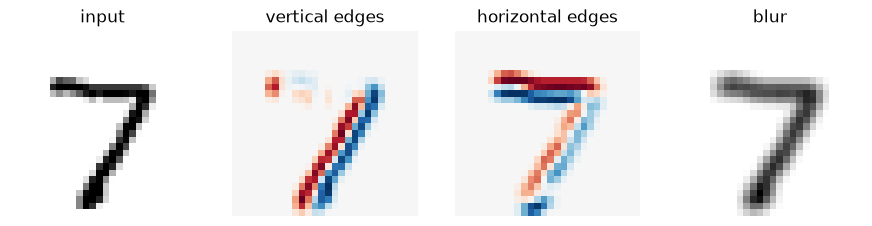

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3))
axes[0].imshow(image[0], cmap="gray_r")
axes[0].set_title("input")
for ax, fmap, title in zip(axes[1:], feature_maps, ["vertical edges", "horizontal edges", "blur"]):
    if title == "blur":
        ax.imshow(fmap, cmap="gray_r")
    else:
        v = fmap.abs().max()
        ax.imshow(fmap, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(title)
for ax in axes:
    ax.axis("off")
plt.show()

The vertical edge detector is positive (red) on the left side of strokes
and negative (blue) on their right side; the horizontal bar of the 7 has
no vertical edges, so it disappears.

## The layers of a CNN

A CNN is built from five kinds of layers (Prince 2023, ch. 10):

- **Convolution** (`nn.Conv2d`): applies several kernels to its input,
  and each kernel produces one output image, called a *channel* or
  *feature map*, that is large where the input looks like the kernel.
  Each kernel looks at all the input channels at once, so a layer from
  $C_{\text{in}}$ to $C_{\text{out}}$ channels with $K \times K$ kernels
  has $K^2 C_{\text{in}} C_{\text{out}} + C_{\text{out}}$ parameters,
  whatever the size of the image. Because the same kernels are used at
  every position, a pattern is detected wherever it appears: shifting
  the input shifts the feature maps by the same amount (*translation
  equivariance*).
- **ReLU** (`nn.ReLU`): replaces every negative number by zero, as in
  section 1. Without it, the stacked layers would collapse into a single
  linear function.
- **Max pooling** (`nn.MaxPool2d(2)`): keeps the largest value in each
  $2 \times 2$ block of each channel, which halves the height and width.
  The next layers then see larger regions of the input (edges, then
  pieces of strokes, then whole digits), and small shifts of the input
  matter less.
- **Flatten** (`nn.Flatten`): lines up the $C \times H \times W$ numbers
  of the last feature maps into one vector of length $CHW$, so that
  fully connected layers can follow.
- **Fully connected** (`nn.Linear`): as in sections 1 and 2, each output
  is a weighted sum of all the inputs plus a bias, so a layer from
  $n_{\text{in}}$ to $n_{\text{out}}$ units has
  $(n_{\text{in}} + 1) \, n_{\text{out}}$ parameters. The last one
  outputs the 10 logits: it is a logistic regression on the features
  computed by the layers before it.

ReLU, pooling and flatten have no parameters. Our CNN repeats
convolution, ReLU and pooling three times, with more channels as the
images get smaller, and ends with two fully connected layers.
`nn.Sequential` chains the layers, and `print_shapes` prints the output
shape and number of parameters of each layer:

In [20]:
def print_shapes(model):
    """Pass one image through the network, printing the output shape and number of parameters of each layer."""
    x = torch.zeros(1, 1, 28, 28)
    print(f"{'input':<12}{str(tuple(x.shape[1:])):<16}")
    for layer in model:
        x = layer(x)
        n_params = sum(p.numel() for p in layer.parameters())
        print(f"{layer.__class__.__name__:<12}{str(tuple(x.shape[1:])):<16}{n_params:>9,} parameters")
    print(f"{'total':<28}{sum(p.numel() for p in model.parameters()):>9,} parameters")

In [21]:
def make_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # 1 x 28 x 28 -> 16 x 14 x 14
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # -> 32 x 7 x 7
        nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # -> 64 x 3 x 3
        nn.Flatten(),                                                               # -> 64 * 3 * 3 = 576
        nn.Linear(64 * 3 * 3, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )


print_shapes(make_cnn())

input       (1, 28, 28)     
Conv2d      (16, 28, 28)          160 parameters
ReLU        (16, 28, 28)            0 parameters
MaxPool2d   (16, 14, 14)            0 parameters
Conv2d      (32, 14, 14)        4,640 parameters
ReLU        (32, 14, 14)            0 parameters
MaxPool2d   (32, 7, 7)              0 parameters
Conv2d      (64, 7, 7)         18,496 parameters
ReLU        (64, 7, 7)              0 parameters
MaxPool2d   (64, 3, 3)              0 parameters
Flatten     (576,)                  0 parameters
Linear      (64,)              36,928 parameters
ReLU        (64,)                   0 parameters
Linear      (10,)                 650 parameters
total                          60,874 parameters

The first fully connected layer has more parameters than all the
convolutions together: shared weights make convolutions cheap, while a
fully connected layer pays for every entry of its input.

# Training a CNN on MNIST

## Comparing the three models

We train the CNN with the same training loop and number of epochs, and
compare the three models.

In [22]:
print("convolutional")
torch.manual_seed(0)
models["convolutional"] = make_cnn()
histories["convolutional"] = train(models["convolutional"], train_loader, N_EPOCHS)

convolutional
  epoch  1: training loss 0.424, validation loss 0.122, validation accuracy 96.3%
  epoch  2: training loss 0.091, validation loss 0.076, validation accuracy 97.7%
  epoch  3: training loss 0.065, validation loss 0.056, validation accuracy 98.3%
  epoch  4: training loss 0.049, validation loss 0.044, validation accuracy 98.7%
  epoch  5: training loss 0.041, validation loss 0.043, validation accuracy 98.8%

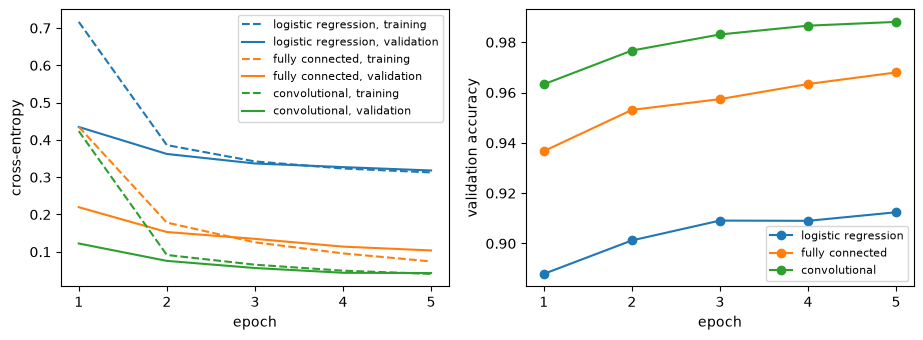

logistic regression     7,850 parameters,  test accuracy 91.9%
fully connected       118,282 parameters,  test accuracy 97.3%
convolutional          60,874 parameters,  test accuracy 98.7%

In [23]:
epochs = range(1, N_EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for i, (name, h) in enumerate(histories.items()):
    axes[0].plot(epochs, h["train_loss"], "--", color=f"C{i}", label=f"{name}, training")
    axes[0].plot(epochs, h["val_loss"], "-", color=f"C{i}", label=f"{name}, validation")
    axes[1].plot(epochs, h["val_acc"], "o-", color=f"C{i}", label=name)
axes[0].set(xlabel="epoch", ylabel="cross-entropy", xticks=epochs)
axes[1].set(xlabel="epoch", ylabel="validation accuracy", xticks=epochs)
axes[0].legend(fontsize=8)
axes[1].legend(fontsize=8)
plt.show()

for name, model in models.items():
    n_params = sum(p.numel() for p in model.parameters())
    _, test_acc = evaluate(model, test_loader)
    print(f"{name:<20} {n_params:>8,} parameters,  test accuracy {test_acc:.1%}")

The CNN makes about half as many test errors as the fully connected
network with half as many parameters, and both are far ahead of logistic
regression. (The training losses of the first epochs are above the
validation losses because they are averaged over an epoch during which
the network improved.)

## Overfitting and early stopping

Here none of the networks overfits: the training and validation losses
are close, and still going down. With less data or many more epochs, the
training loss keeps going down as the network memorizes the training
images, while the validation loss reaches a minimum and then goes back
up. *Early stopping* keeps the network from the epoch with the lowest
validation loss (Prince 2023, sec. 9.3.1): the number of epochs is a
hyperparameter, chosen with the validation set. More generally, the
validation set is how we choose between models, for example between
architectures, while the test set stays untouched until the end.

The validation loss can go up a lot while the validation accuracy stays
almost flat. Once the training data is fit perfectly, training keeps
pushing the predicted probabilities towards 0 and 1. The predicted
classes barely change, but the network becomes more confident, including
in its mistakes, and the cross-entropy
$-\log \mathbb{P}_{\,}\left(y \mid \boldsymbol{x}\right)$ of a confident
mistake is large.

## Robustness to shifts

Next we evaluate the trained models on test images shifted by $k$
pixels, averaging over shifts left, right, up and down.

logistic regression  shift 0: 91.9%,  shift 1: 84.9%,  shift 2: 59.6%,  shift 3: 33.0%,  shift 4: 16.9%
fully connected      shift 0: 97.3%,  shift 1: 93.5%,  shift 2: 76.0%,  shift 3: 48.6%,  shift 4: 26.4%
convolutional        shift 0: 98.7%,  shift 1: 98.2%,  shift 2: 95.7%,  shift 3: 88.0%,  shift 4: 72.6%

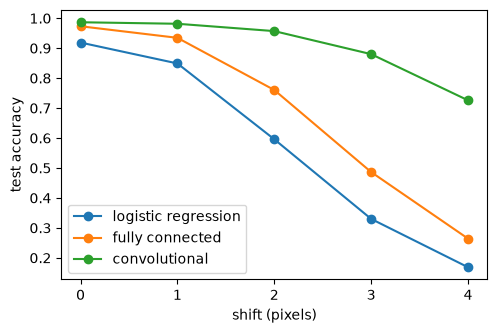

In [24]:
def shift(images, dx=0, dy=0):
    """Translate images (last two dimensions 28 x 28) by dx pixels right and dy pixels down, filling with zeros."""
    out = torch.roll(images, shifts=(dy, dx), dims=(-2, -1))
    if dy > 0:
        out[..., :dy, :] = 0
    if dy < 0:
        out[..., dy:, :] = 0
    if dx > 0:
        out[..., :, :dx] = 0
    if dx < 0:
        out[..., :, dx:] = 0
    return out


def shift_accuracy(model, k):
    """Test accuracy on images shifted by k pixels, averaged over the four directions."""
    return np.mean([evaluate(model, test_loader, transform=lambda imgs: shift(imgs, dx, dy))[1]
                    for dx, dy in [(k, 0), (-k, 0), (0, k), (0, -k)]])


shifts = [0, 1, 2, 3, 4]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
for name, model in models.items():
    accs = [shift_accuracy(model, k) for k in shifts]
    ax.plot(shifts, accs, "o-", label=name)
    print(f"{name:<20} " + ",  ".join(f"shift {k}: {a:.1%}" for k, a in zip(shifts, accs)))
ax.set(xlabel="shift (pixels)", ylabel="test accuracy", xticks=shifts)
ax.legend()
plt.show()

At a 3-pixel shift, logistic regression and the fully connected network
get only about a third and a half of the test images right, while the
CNN still gets nearly nine in ten. Convolutions and pooling make the CNN
robust to small shifts, but not invariant: it was trained on centered
digits, and its fully connected layers depend on location.

## What convolutions assume

The CNN’s advantages rest on an assumption: nearby pixels are related,
and a local pattern (an edge, the end of a stroke) means the same thing
wherever it appears. This holds for images, so sharing weights across
positions costs nothing. If we scrambled the pixels as in section 3, the
fully connected network would not notice, but the CNN’s $3 \times 3$
patches would become sets of unrelated pixels from all over the image,
and it would lose its advantage.

Cybenko, George. 1989. “Approximation by Superpositions of a Sigmoidal
Function.” *Mathematics of Control, Signals and Systems* 2 (4): 303–14.

Hanin, Boris, and David Rolnick. 2019. “Deep ReLU Networks Have
Surprisingly Few Activation Patterns.” *Advances in Neural Information
Processing Systems* 32.

Hornik, Kurt. 1991. “Approximation Capabilities of Multilayer
Feedforward Networks.” *Neural Networks* 4 (2): 251–57.

Kingma, Diederik P., and Jimmy Ba. 2015. “Adam: A Method for Stochastic
Optimization.” *International Conference on Learning Representations*.

LeCun, Yann, Léon Bottou, Yoshua Bengio, and Patrick Haffner. 1998.
“Gradient-Based Learning Applied to Document Recognition.” *Proceedings
of the IEEE* 86 (11): 2278–324.

Leshno, Moshe, Vladimir Ya. Lin, Allan Pinkus, and Shimon Schocken.
1993. “Multilayer Feedforward Networks with a Nonpolynomial Activation
Function Can Approximate Any Function.” *Neural Networks* 6 (6): 861–67.

Montúfar, Guido, Razvan Pascanu, Kyunghyun Cho, and Yoshua Bengio. 2014.
“On the Number of Linear Regions of Deep Neural Networks.” *Advances in
Neural Information Processing Systems* 27.

Prince, Simon J. D. 2023. *Understanding Deep Learning*. The MIT Press.
<http://udlbook.com>.

Rumelhart, David E., Geoffrey E. Hinton, and Ronald J. Williams. 1986.
“Learning Representations by Back-Propagating Errors.” *Nature* 323
(6088): 533–36.